# Decision Trees Exercises

![DecisionTree.png](./Assets/DecisionTree.png)


# Цели обучения

- Распознайте деревья решений и как их использовать для проблем классификации
- Узнайте, как определить наилучшее разделение и факторы для разделения
- Объясните сильные и слабые стороны деревьев для принятия решений
- Объясните, как деревья регрессии помогают классифицировать непрерывные значения
- Примените расширение Intel® для Scikit-learn*, чтобы использовать базовые вычислительные возможности оборудования




## Введение

Мы будем использовать набор данных качества вина для этих упражнений. Этот набор данных содержит различные химические свойства вина, такие как кислотность, сахар, pH и алкоголь. Он также содержит метрику качества (3-9, где самый высокий - лучше) и цвет (красный или белый). Имя файла - «Wine_Quality_Data.csv».

In [2]:
from __future__ import print_function
import os
data_path = ['data']

from io import StringIO
from IPython.display import Image, display

from sklearn.tree import export_graphviz
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier

from sklearnex import patch_sklearn
patch_sklearn()

Extension for scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


## Вопрос 1

* Импортируйте данные и изучите функции.
* Мы будем использовать их все для прогнозирования `color` (белого или красного), но функция цветов должна быть закодирована на целое число.

Преобразуйте цветовую функцию в целое число. Это быстрый способ сделать это с помощью  Pandas.

In [9]:
import pandas as pd

data = pd.read_csv("./data/Wine_Quality_Data.csv")

print(data.head())
print(data.info())
print(data.columns)

data['color'] = data['color'].map({'white': 0, 'red': 1})
print(data.head())


   fixed_acidity  volatile_acidity  citric_acid  residual_sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free_sulfur_dioxide  total_sulfur_dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality color  
0      9.4        5   red  
1      9.8        5   red  
2 

## Вопрос 2

* Используйте `StratifiedShuffleSplit` для разделения данных на наборы поездов и тестов, которые стратифицированы по качеству вина. Если возможно, сохраните индексы доли для вопроса 5 ниже.
* Проверьте процентный состав каждого уровня качества для наборов данных о поезде и тестовых данных.

Теперь проверьте процентную долю каждого уровня качества в обучающем и тестовом наборах данных. Как видно ниже, набор данных в основном состоит из белого вина.

In [14]:
X = data.drop('quality', axis=1)
y = data['quality']

split = StratifiedShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

for train_index, test_index in split.split(X, y):
    train_set = data.iloc[train_index]
    test_set = data.iloc[test_index]

train_indices = train_index
test_indices = test_index

print("Распределение качества в исходном наборе данных (%):")
print((data['quality'].value_counts(normalize=True) * 100).sort_index().round(2))

print("\nРаспределение качества в обучающей выборке (%):")
print((train_set['quality'].value_counts(normalize=True) * 100).sort_index().round(2))

print("\nРаспределение качества в тестовой выборке (%):")
print((test_set['quality'].value_counts(normalize=True) * 100).sort_index().round(2))


Распределение качества в исходном наборе данных (%):
quality
3     0.46
4     3.32
5    32.91
6    43.65
7    16.61
8     2.97
9     0.08
Name: proportion, dtype: float64

Распределение качества в обучающей выборке (%):
quality
3     0.46
4     3.33
5    32.90
6    43.66
7    16.61
8     2.96
9     0.08
Name: proportion, dtype: float64

Распределение качества в тестовой выборке (%):
quality
3     0.46
4     3.31
5    32.92
6    43.62
7    16.62
8     3.00
9     0.08
Name: proportion, dtype: float64


## Вопрос 3

* Постройте классификатор на основе дерева решений без ограничений на максимальную глубину, количество признаков или количество листьев.
* Определите, сколько узлов присутствует в этом (очень большом) дереве и какова его глубина.
* Используя это дерево, оцените погрешность прогнозирования на обучающем и тестовом наборах данных. Как вы думаете, что здесь происходит, исходя из различий в погрешности прогнозирования?

Количество узлов и максимальная фактическая глубина.

In [ ]:
X_train = train_set.drop('color', axis=1)
y_train = train_set['color']

X_test = test_set.drop('color', axis=1)
y_test = test_set['color']

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

print("Количество узлов:", tree.tree_.node_count)
print("Максимальная фактическая глубина:", tree.tree_.max_depth)

train_accuracy = accuracy_score(y_train, tree.predict(X_train))
test_accuracy = accuracy_score(y_test, tree.predict(X_test))

print("Точность на обучающей выборке:", train_accuracy)
print("Точность на тестовой выборке:", test_accuracy)

print("Ошибка на обучающей выборке:", 1 - train_accuracy)
print("Ошибка на тестовой выборке:", 1 - test_accuracy)

Количество узлов: 151
Максимальная фактическая глубина: 21
Точность на обучающей выборке: 0.9996151625938041
Точность на тестовой выборке: 0.9853846153846154
Ошибка на обучающей выборке: 0.00038483740619588147
Ошибка на тестовой выборке: 0.014615384615384586


Дерево решений демонстрирует чуть более точные прогнозы на обучающих данных, чем на тестовых, что свидетельствует о (незначительной) переобученности. Также обратите внимание на идеальный показатель воспроизводимости для обучающих данных. Во многих случаях разница в точности прогнозов бывает даже больше, чем показано здесь.

## Вопрос 4

* С помощью сетчатого поиска с перекрестной валидацией найдите дерево решений, которое демонстрирует хорошие результаты на тестовом наборе данных. Присвойте этой модели дерева решений другое имя переменной, чем в вопросе 3, чтобы обе модели можно было использовать в вопросе 6.
* Определите количество узлов и глубину этого дерева.
* Рассчитайте погрешности на обучающем и тестовом наборах данных, как и ранее, и сравните их с погрешностями дерева из вопроса 3.

Количество узлов и максимальная глубина дерева.

Эти ошибки тестирования немного лучше, чем предыдущие. Таким образом, можно сделать вывод, что в предыдущем примере имело место переобучение, но лишь в незначительной степени.

In [ ]:
param_grid = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

tree_clf_grid = DecisionTreeClassifier(random_state=42)

grid_search = GridSearchCV(
    estimator=tree_clf_grid,
    param_grid=param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

best_tree_clf = grid_search.best_estimator_

print("Лучшие параметры:", grid_search.best_params_)
print("Лучшая средняя точность CV:", grid_search.best_score_)

print("Количество узлов:", best_tree_clf.tree_.node_count)
print("Максимальная глубина:", best_tree_clf.tree_.max_depth)

train_accuracy = accuracy_score(
    y_train, best_tree_clf.predict(X_train)
)
test_accuracy = accuracy_score(
    y_test, best_tree_clf.predict(X_test)
)

print("Точность на обучении:", train_accuracy)
print("Точность на тесте:", test_accuracy)

print("Ошибка на обучении:", 1 - train_accuracy)
print("Ошибка на тесте:", 1 - test_accuracy)

print("\nСравнение с исходным деревом:")
print("Исходное дерево — узлы:", tree.tree_.node_count)
print("Исходное дерево — глубина:", tree.tree_.max_depth)
print("Исходное дерево — ошибка обучения:",
      1 - accuracy_score(y_train, tree.predict(X_train)))
print("Исходное дерево — ошибка теста:",
      1 - accuracy_score(y_test, tree.predict(X_test)))

Лучшие параметры: {'max_depth': 7, 'min_samples_leaf': 1, 'min_samples_split': 2}
Лучшая средняя точность CV: 0.9880698896868291
Количество узлов: 67
Максимальная глубина: 7
Точность на обучении: 0.993650182797768
Точность на тесте: 0.9853846153846154
Ошибка на обучении: 0.006349817202232044
Ошибка на тесте: 0.014615384615384586

Сравнение с исходным деревом:
Исходное дерево — узлы: 151
Исходное дерево — глубина: 21
Исходное дерево — ошибка обучения: 0.00038483740619588147
Исходное дерево — ошибка теста: 0.014615384615384586


## Вопрос 5

* Снова разделите данные на части `X` и `y`, на этот раз с `residual_sugar` в качестве прогнозируемых (`y`) данных. *Примечание:* если индексы были сохранены из результатов `StratifiedShuffleSplit` в вопросе 2, их можно использовать повторно для разделения данных.
* Используя поиск по сетке с перекрестной валидацией, найдите модель **регрессии** на основе дерева решений, которая хорошо работает на тестовом наборе данных.
* Оцените погрешности на обучающем и тестовом наборах данных с помощью среднеквадратичной ошибки.
* Постройте график, на котором будут отображены фактические *и* прогнозируемые значения остаточного сахара.

Количество узлов и максимальная глубина дерева. В этом дереве много узлов, что неудивительно, учитывая непрерывный характер данных.

Ошибка на обучающем и тестовом наборах данных. Поскольку речь идет о непрерывных величинах, мы будем использовать среднеквадратичную ошибку.

График, отражающий соотношение фактического и прогнозируемого остаточного содержания сахара.

Лучшие параметры: {'max_depth': 15, 'min_samples_leaf': 4, 'min_samples_split': 10}
Лучшая глубина: 15
Количество узлов: 1627

MSE на обучении: 0.7553503147500317
MSE на тесте: 2.9500379023202212


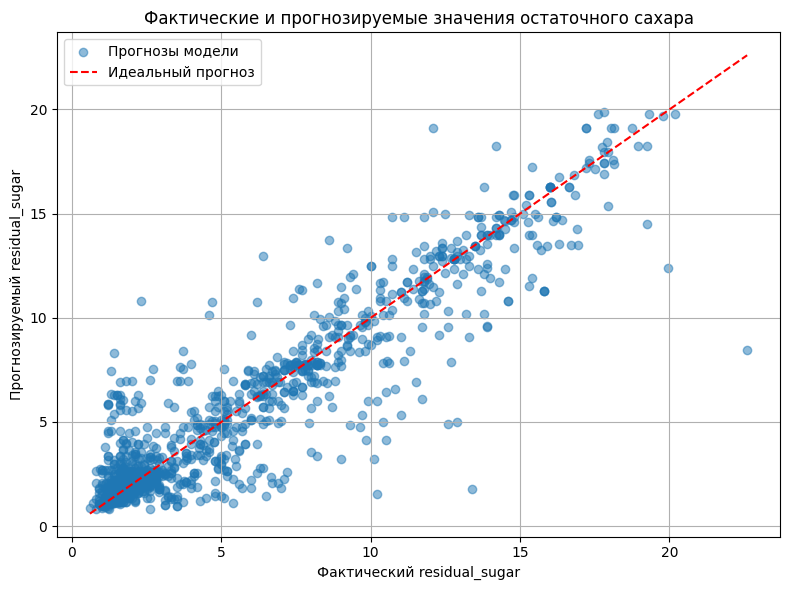

In [ ]:
import matplotlib.pyplot as plt


X = data.drop('residual_sugar', axis=1)
y = data['residual_sugar']

X_train = X.loc[train_indices]
X_test = X.loc[test_indices]

y_train = y.loc[train_indices]
y_test = y.loc[test_indices]

param_grid = {
    'max_depth': [3, 5, 7, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

tree_reg = DecisionTreeRegressor(random_state=42)

grid_search_reg = GridSearchCV(
    estimator=tree_reg,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid_search_reg.fit(X_train, y_train)

best_tree_reg = grid_search_reg.best_estimator_

print("Лучшие параметры:", grid_search_reg.best_params_)
print("Лучшая глубина:", best_tree_reg.tree_.max_depth)
print("Количество узлов:", best_tree_reg.tree_.node_count)

y_train_pred = best_tree_reg.predict(X_train)
y_test_pred = best_tree_reg.predict(X_test)

train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

print("\nMSE на обучении:", train_mse)
print("MSE на тесте:", test_mse)

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.5,
    label='Прогнозы модели'
)

min_value = min(y_test.min(), y_test_pred.min())
max_value = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'r--',
    label='Идеальный прогноз'
)

plt.xlabel('Фактический residual_sugar')
plt.ylabel('Прогнозируемый residual_sugar')
plt.title('Фактические и прогнозируемые значения остаточного сахара')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## Вопрос 6 *(Необязательный)*

Этот вопрос является необязательным, так как для его решения требуется дополнительная программа командной строки (GraphViz) и библиотека Python (PyDotPlus). GraphViz можно установить с помощью менеджера пакетов в Linux и Mac. Для установки библиотеки PyDotPlus можно использовать либо `pip`, либо `conda` (`conda install -c conda-forge pydotplus`).

После установки этих программ:

* Создайте визуализацию дерева решений из вопроса 3, в котором предсказывался цвет вина, а количество признаков и/или разбиений не ограничено.
* Создайте визуализацию дерева решений из вопроса 4, в котором предсказывался цвет вина, но для нахождения оптимальной глубины и количества признаков использовался поиск по сетке.

Дерево решений из вопроса 5, скорее всего, будет иметь слишком много узлов для визуализации.

In [24]:
try:
    import pydotplus
    pydotplus_installed = True
    
except:
    print('PyDotPlus must be installed to execute the remainder of the cells associated with this question.')
    print('Please see the instructions for this question for details.')
    pydotplus_installed = False

Дерево из вопроса 3.

Дерево, построенное с помощью перекрестной валидации из вопроса 4. Это дерево намного менее глубокое, чем предыдущее.